# LEAF-1 mean pooling against the published SnapATAC pipeline

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

The reviewer asked for a benchmark against a state-of-the-art scATAC workflow
under matched fragment sampling. Both representations were built from the same
10,131 cells and the same 1,000 fragments per cell, scored on the atlas's own
predefined folds with the same classifier, so the only variable is the
representation. One dot per one-vs-all task, against y = x.

The two panels differ only in what the dot **size** encodes:

- `scatac_leaf1_vs_snapatac_auc`: positive cells, so a thin task is visibly thin.
- `scatac_leaf1_vs_snapatac_auc_ntissues`: how many distinct biosamples the cell
  type appears in. This is the only candidate that actually tracks the gap
  (r = +0.52, p = 2e-08), so it is the one encoding whose size channel earns
  its place.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: scatac/data
OUT : scatac/output


In [2]:
# ── Constants, data and the shared panel function ─────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, wilcoxon

# LEAF-1 takes the blue it has in every other figure; SnapATAC keeps the
# green of the scIB charts.
LEAF, SNAP = OKABE_ITO["blue"], OKABE_ITO["green"]
INK, MUTED, GRID = "#1A1A1A", "#666666", "#D9D9D9"
A_NAME, B_NAME = "LEAF-1 mean pooling", "SnapATAC 5 kb + MNC"
SUBTITLE = "identical cells and fragments"
PANEL_RC = {
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6.5,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 5.5,
}
SIZE_LABEL = {"n_case": "positive cells", "n_tissues": "biosamples spanned"}

m = pd.read_csv(DATA / "scatac_atlas_supervised_auc.csv").rename(
    columns={"auc_leaf1": "auc_a", "auc_snapatac": "auc_b"})
m = m.dropna(subset=["auc_a", "auc_b"])
m["delta"] = m.auc_b - m.auc_a
print(f"{len(m)} tasks   {A_NAME} {m.auc_a.mean():.4f}   "
      f"{B_NAME} {m.auc_b.mean():.4f}   delta {m.delta.mean():+.4f}")
print(f"  {B_NAME} higher in {int((m.delta > 0).sum())}/{len(m)} tasks   "
      f"Wilcoxon p = {wilcoxon(m.auc_a, m.auc_b).pvalue:.2e}")


def auc_scatter(size_col, stem):
    """One dot per task against y = x, dot area encoding ``size_col``."""
    size_label = SIZE_LABEL[size_col]
    # No size variable here has a meaningful zero, so area spans the observed
    # range rather than being anchored at an absolute floor.
    floor = m[size_col].min()
    v = m[size_col]
    span = max(v.max() - floor, 1e-12)
    to_size = lambda x: 6 + 34 * min(max((x - floor) / span, 0.0), 1.0)  # noqa: E731
    size = ((v - floor) / span).clip(0, 1) * 34 + 6
    wins = m.auc_b > m.auc_a

    with plt.rc_context(PANEL_RC):
        fig, ax = plt.subplots(figsize=(3.5, 3.5))
        lo = min(m.auc_a.min(), m.auc_b.min()) - 0.02
        ax.plot([lo, 1.0], [lo, 1.0], color=MUTED, lw=0.8, ls="--", zorder=1)
        ax.text(1.0, 1.0, "  y = x", color=MUTED, fontsize=5.5, ha="left", va="center")

        ax.scatter(m.auc_a[wins], m.auc_b[wins], s=size[wins], color=SNAP,
                   edgecolor="white", linewidth=0.5, zorder=3,
                   label=f"{B_NAME} higher ({int(wins.sum())})")
        ax.scatter(m.auc_a[~wins], m.auc_b[~wins], s=size[~wins], color=LEAF,
                   edgecolor="white", linewidth=0.5, zorder=3,
                   label=f"{A_NAME} higher ({int((~wins).sum())})")

        ax.set_xlim(lo, 1.005); ax.set_ylim(lo, 1.005); ax.set_aspect("equal")
        ax.set_xlabel(f"AUC, {A_NAME}")
        ax.set_ylabel(f"AUC, {B_NAME}")
        ax.set_title(f"{len(m)} one-vs-all tasks, {SUBTITLE}\n"
                     f"mean AUC {m.auc_a.mean():.4f} vs {m.auc_b.mean():.4f}"
                     f"   (r = {m.auc_a.corr(m.auc_b):.3f})",
                     loc="left", color=INK)
        ax.grid(True, color=GRID, lw=0.4); ax.set_axisbelow(True)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        for s in ("left", "bottom"):
            ax.spines[s].set_color(MUTED)
        ax.tick_params(colors=MUTED, width=0.5, length=2)
        color_leg = ax.legend(frameon=False, loc="lower right", handletextpad=0.3,
                              borderpad=0.2, labelspacing=0.3, title=None,
                              title_fontsize=5.5, alignment="left")
        ax.add_artist(color_leg)

        # Size is meaningless without a key.
        ticks = [floor, (floor + v.max()) / 2, v.max()]
        handles = [ax.scatter([], [], s=to_size(t), color=MUTED,
                              edgecolor="white", linewidth=0.5, label=f"{t:.0f}")
                   for t in ticks]
        ax.legend(handles=handles, title=size_label, frameon=False, loc="upper left",
                  handletextpad=0.4, borderpad=0.2, labelspacing=0.6,
                  title_fontsize=5.5, alignment="left")
        fig.tight_layout()
        savefig(fig, OUT, stem,
                data=m[["task", "case_label", "auc_a", "auc_b", "delta", size_col]]
                      .rename(columns={"auc_a": "auc_leaf1", "auc_b": "auc_snapatac"}))
        plt.show()

    print(f"  size = {size_label}: {m[size_col].min():.3f} - {m[size_col].max():.3f}")
    for col in ("auc_a", "auc_b", "delta"):
        r, pr = pearsonr(m[size_col], m[col])
        rs, ps = spearmanr(m[size_col], m[col])
        print(f"    vs {col:<6} pearson r = {r:+.3f} (p = {pr:.1e})   "
              f"spearman r = {rs:+.3f} (p = {ps:.1e})")

102 tasks   LEAF-1 mean pooling 0.9253   SnapATAC 5 kb + MNC 0.9490   delta +0.0237
  SnapATAC 5 kb + MNC higher in 72/102 tasks   Wilcoxon p = 1.06e-05


saved: scatac/output/scatac_leaf1_vs_snapatac_auc.pdf
saved: scatac/output/scatac_leaf1_vs_snapatac_auc.png
saved: scatac/output/scatac_leaf1_vs_snapatac_auc.svg
saved: scatac/output/scatac_leaf1_vs_snapatac_auc.tsv


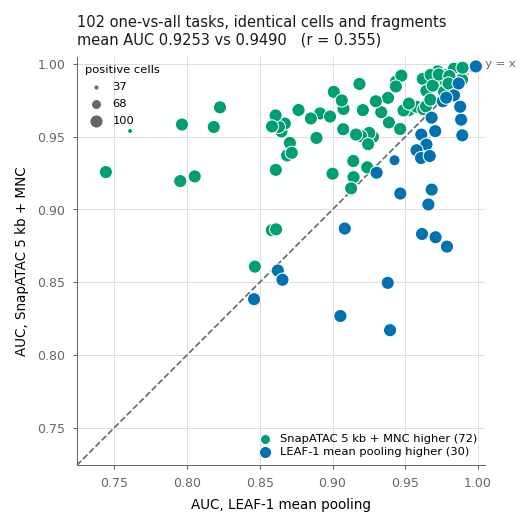

  size = positive cells: 37.000 - 100.000
    vs auc_a  pearson r = +0.271 (p = 5.9e-03)   spearman r = +0.116 (p = 2.4e-01)
    vs auc_b  pearson r = +0.001 (p = 9.9e-01)   spearman r = +0.074 (p = 4.6e-01)
    vs delta  pearson r = -0.267 (p = 6.6e-03)   spearman r = -0.050 (p = 6.2e-01)


In [3]:
# ── Dot size = number of positive cells ───────────────────────────────────────
auc_scatter("n_case", "scatac_leaf1_vs_snapatac_auc")

saved: scatac/output/scatac_leaf1_vs_snapatac_auc_ntissues.pdf
saved: scatac/output/scatac_leaf1_vs_snapatac_auc_ntissues.png
saved: scatac/output/scatac_leaf1_vs_snapatac_auc_ntissues.svg
saved: scatac/output/scatac_leaf1_vs_snapatac_auc_ntissues.tsv


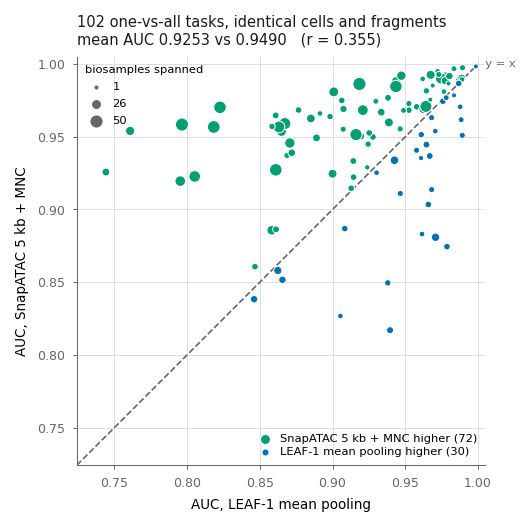

  size = biosamples spanned: 1.000 - 50.000
    vs auc_a  pearson r = -0.480 (p = 3.2e-07)   spearman r = -0.522 (p = 1.8e-08)
    vs auc_b  pearson r = +0.062 (p = 5.4e-01)   spearman r = -0.125 (p = 2.1e-01)
    vs delta  pearson r = +0.521 (p = 2.0e-08)   spearman r = +0.501 (p = 8.2e-08)


In [4]:
# ── Dot size = number of biosamples the cell type spans ───────────────────────
# Sampling on this atlas is organ-driven, so a type that recurs across many
# biosamples is the one SnapATAC's feature selection has the most to work with.
auc_scatter("n_tissues", "scatac_leaf1_vs_snapatac_auc_ntissues")